# IPL Deliveries Data Analysis - Part 2
## Advanced Exploratory Data Analysis (EDA) using Python

In this project we analyse **ball-by-ball IPL data** (`deliveries.csv`) using Pandas, Matplotlib and Seaborn.
This time we look at **strike rates, boundary and dot-ball percentages, bowling economy, match phases, innings comparison, partnerships, wicket patterns and fielders**.

**Note:** keep `deliveries.csv` in the same folder as this notebook.

In [30]:
# Step 1: Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

## 1. Load the dataset

In [31]:
# Step 2: Read the CSV file
data = pd.read_csv("/content/deliveries.csv")

print("Rows    :", data.shape[0])
print("Columns :", data.shape[1])
data.head()

Rows    : 179078
Columns : 21


,match_id,inning,batting_team,bowling_team,over,ball,batsman,non_striker,bowler,is_super_over,...,bye_runs,legbye_runs,noball_runs,penalty_runs,batsman_runs,extra_runs,total_runs,player_dismissed,dismissal_kind,fielder
0,1,1,Sunrisers Hyderabad,Royal Challengers Bangalore,1,1,DA Warner,S Dhawan,TS Mills,0,...,0,0,0,0,0,0,0,NaN,NaN,NaN
1,1,1,Sunrisers Hyderabad,Royal Challengers Bangalore,1,2,DA Warner,S Dhawan,TS Mills,0,...,0,0,0,0,0,0,0,NaN,NaN,NaN
2,1,1,Sunrisers Hyderabad,Royal Challengers Bangalore,1,3,DA Warner,S Dhawan,TS Mills,0,...,0,0,0,0,4,0,4,NaN,NaN,NaN
3,1,1,Sunrisers Hyderabad,Royal Challengers Bangalore,1,4,DA Warner,S Dhawan,TS Mills,0,...,0,0,0,0,0,0,0,NaN,NaN,NaN
4,1,1,Sunrisers Hyderabad,Royal Challengers Bangalore,1,5,DA Warner,S Dhawan,TS Mills,0,...,0,0,0,0,0,2,2,NaN,NaN,NaN


## 2. Understand the data

In [32]:
# Column names and data types
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 179078 entries, 0 to 179077
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype 
---  ------            --------------   ----- 
 0   match_id          179078 non-null  int64 
 1   inning            179078 non-null  int64 
 2   batting_team      179078 non-null  object
 3   bowling_team      179078 non-null  object
 4   over              179078 non-null  int64 
 5   ball              179078 non-null  int64 
 6   batsman           179078 non-null  object
 7   non_striker       179078 non-null  object
 8   bowler            179078 non-null  object
 9   is_super_over     179078 non-null  int64 
 10  wide_runs         179078 non-null  int64 
 11  bye_runs          179078 non-null  int64 
 12  legbye_runs       179078 non-null  int64 
 13  noball_runs       179078 non-null  int64 
 14  penalty_runs      179078 non-null  int64 
 15  batsman_runs      179078 non-null  int64 
 16  extra_runs        179078 non-null  int

In [33]:
# Missing values and duplicate rows
print("Missing values in each column:")
print(data.isnull().sum())
print()
print("Duplicate rows:", data.duplicated().sum())

Missing values in each column:
match_id                 0
inning                   0
batting_team             0
bowling_team             0
over                     0
ball                     0
batsman                  0
non_striker              0
bowler                   0
is_super_over            0
wide_runs                0
bye_runs                 0
legbye_runs              0
noball_runs              0
penalty_runs             0
batsman_runs             0
extra_runs               0
total_runs               0
player_dismissed    170244
dismissal_kind      170244
fielder             172630
dtype: int64

Duplicate rows: 23


**Note:** `player_dismissed`, `dismissal_kind` and `fielder` are empty on most balls because a wicket does not fall on every ball. This is normal, so we do not remove these rows.

## 3. Prepare helper columns
We create a few new columns that we will use again and again:
- **legal_ball** : a ball that counts in an over (not a wide, not a no-ball)
- **faced_ball** : a ball faced by the batter (everything except wides)
- **bowler_runs** : runs charged to the bowler (byes, leg-byes and penalty runs are not charged)
- **phase** : Powerplay (overs 1-6), Middle (7-15) or Death (16-20)

In [34]:
# Step 3: Create helper columns
data["legal_ball"] = (data["wide_runs"] == 0) & (data["noball_runs"] == 0)
data["faced_ball"] = data["wide_runs"] == 0
data["bowler_runs"] = data["total_runs"] - data["bye_runs"] - data["legbye_runs"] - data["penalty_runs"]

def get_phase(over):
    if over <= 6:
        return "Powerplay (1-6)"
    elif over <= 15:
        return "Middle (7-15)"
    else:
        return "Death (16-20)"

data["phase"] = data["over"].apply(get_phase)
data[["over", "phase", "legal_ball", "faced_ball", "bowler_runs"]].head()

,over,phase,legal_ball,faced_ball,bowler_runs
0,1,Powerplay (1-6),True,True,0
1,1,Powerplay (1-6),True,True,0
2,1,Powerplay (1-6),True,True,4
3,1,Powerplay (1-6),True,True,0
4,1,Powerplay (1-6),False,False,2


## 4. Match and innings statistics

In [35]:
matches = data["match_id"].nunique()
match_runs = data.groupby("match_id")["total_runs"].sum()

print("Total matches                :", matches)
print("Average runs per match       :", round(match_runs.mean(), 2))
print("Highest runs in a match      :", match_runs.max())
print("Lowest runs in a match       :", match_runs.min())
print("Super over deliveries        :", (data["is_super_over"] == 1).sum())

Total matches                : 756
Average runs per match       : 311.23
Highest runs in a match      : 471
Lowest runs in a match       : 56
Super over deliveries        : 81


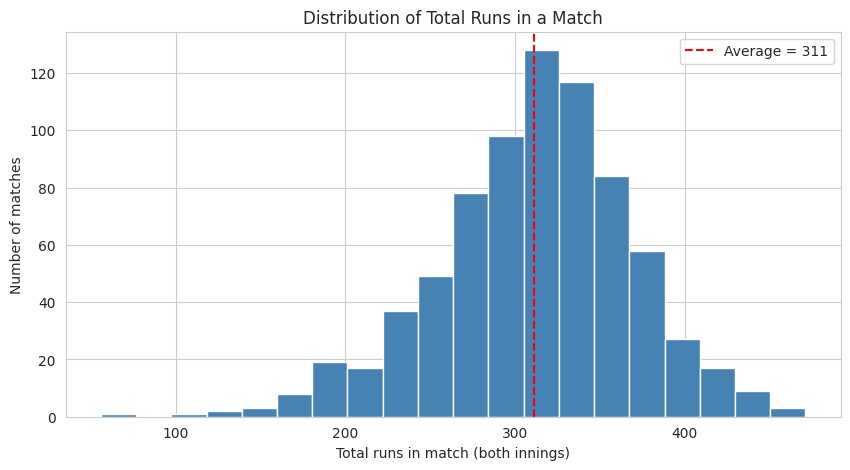

In [36]:
plt.figure(figsize=(10, 5))
plt.hist(match_runs, bins=20, color="steelblue", edgecolor="white")
plt.axvline(match_runs.mean(), color="red", linestyle="--", label=f"Average = {match_runs.mean():.0f}")
plt.title("Distribution of Total Runs in a Match")
plt.xlabel("Total runs in match (both innings)")
plt.ylabel("Number of matches")
plt.legend()
plt.show()

## 5. Batters with the best strike rate

Strike rate = (runs / balls faced) x 100. To keep the list fair, we only include batters who faced at least **500 balls**.

In [37]:
# Step: runs and balls faced by each batter
batter = data.groupby("batsman").agg(
    runs=("batsman_runs", "sum"),
    balls=("faced_ball", "sum")
)

batter = batter[batter["balls"] >= 500]
batter["strike_rate"] = (batter["runs"] / batter["balls"] * 100).round(2)

top_sr = batter.sort_values("strike_rate", ascending=False).head(10)
print("Best strike rate:", top_sr.index[0], "->", top_sr["strike_rate"].iloc[0])
top_sr

Best strike rate: AD Russell -> 191.64


,runs,balls,strike_rate
batsman,,,
AD Russell,1445,754,191.64
RR Pant,1792,1071,167.32
GJ Maxwell,1403,868,161.64
HH Pandya,1118,692,161.56
V Sehwag,2728,1755,155.44
JC Buttler,1431,922,155.21
CH Gayle,4560,2981,152.97
AB de Villiers,4428,2911,152.11
KH Pandya,915,610,150.00


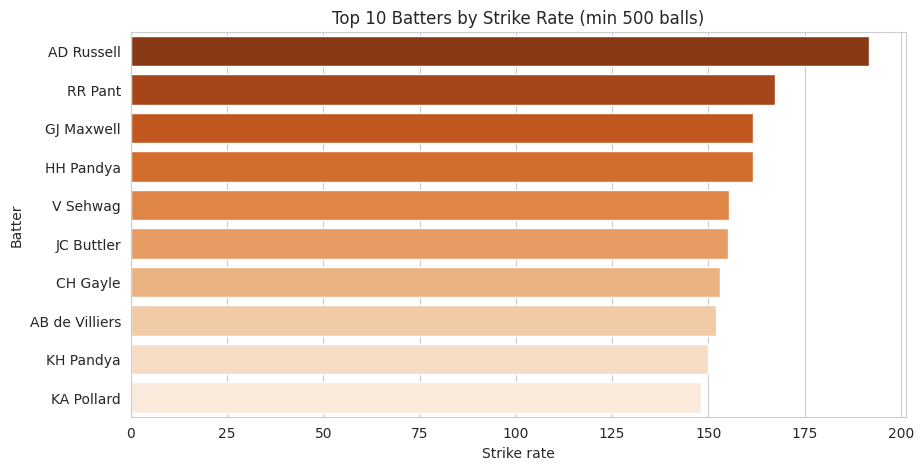

In [38]:
plt.figure(figsize=(10, 5))
sns.barplot(x=top_sr["strike_rate"], y=top_sr.index, hue=top_sr.index, palette="Oranges_r", legend=False)
plt.title("Top 10 Batters by Strike Rate (min 500 balls)")
plt.xlabel("Strike rate")
plt.ylabel("Batter")
plt.show()

## 6. Boundary percentage and dot-ball percentage of batters

In [39]:
# Share of balls faced that went for a four/six, and share that were dot balls
bat_balls = data[data["faced_ball"]]

boundary_pct = bat_balls.groupby("batsman").apply(
    lambda x: (x["batsman_runs"].isin([4, 6])).mean() * 100
)
dot_pct = bat_balls.groupby("batsman").apply(
    lambda x: ((x["total_runs"] == 0)).mean() * 100
)

style = batter.copy()
style["boundary_pct"] = boundary_pct.round(2)
style["dot_pct"] = dot_pct.round(2)

print("Top 10 by boundary %:")
style.sort_values("boundary_pct", ascending=False).head(10)[["balls", "boundary_pct", "dot_pct"]]

Top 10 by boundary %:


/tmp/ipykernel_2296/44302151.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  boundary_pct = bat_balls.groupby("batsman").apply(
/tmp/ipykernel_2296/44302151.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  dot_pct = bat_balls.groupby("batsman").apply(


,balls,boundary_pct,dot_pct
batsman,,,
AD Russell,754,28.78,34.35
V Sehwag,1755,25.07,34.25
CH Gayle,2981,23.58,41.46
GJ Maxwell,868,23.16,32.83
RR Pant,1071,23.16,29.51
ST Jayasuriya,532,23.12,44.36
AC Gilchrist,1495,22.14,42.01
JC Buttler,922,22.13,33.84
CA Lynn,911,20.86,39.85


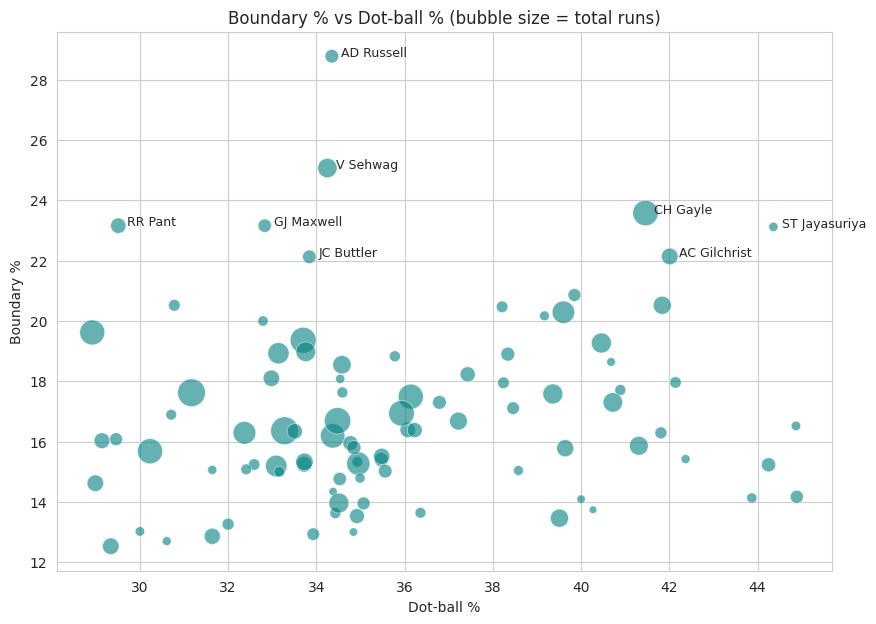

In [40]:
plt.figure(figsize=(10, 7))
sns.scatterplot(data=style, x="dot_pct", y="boundary_pct", size="runs", sizes=(30, 400),
                alpha=0.6, color="teal", legend=False)

# label the 8 batters with the highest boundary %
for name, row in style.nlargest(8, "boundary_pct").iterrows():
    plt.text(row["dot_pct"] + 0.2, row["boundary_pct"], name, fontsize=9)

plt.title("Boundary % vs Dot-ball % (bubble size = total runs)")
plt.xlabel("Dot-ball %")
plt.ylabel("Boundary %")
plt.show()

**Observation:** batters in the top-left of the chart (high boundary %, low dot-ball %) are the most efficient hitters. Batters in the bottom-right play more dot balls and hit fewer boundaries.

## 7. Bowlers with the best economy rate

Economy rate = runs conceded per over (6 legal balls). We include only bowlers who bowled at least **300 legal balls**.

In [41]:
bowler = data.groupby("bowler").agg(
    runs=("bowler_runs", "sum"),
    balls=("legal_ball", "sum")
)

bowler = bowler[bowler["balls"] >= 300]
bowler["economy"] = (bowler["runs"] / (bowler["balls"] / 6)).round(2)

best_economy = bowler.sort_values("economy").head(10)
print("Best economy:", best_economy.index[0], "->", best_economy["economy"].iloc[0])
best_economy

Best economy: A Kumble -> 6.58


,runs,balls,economy
bowler,,,
A Kumble,1058,965,6.58
GD McGrath,357,324,6.61
M Muralitharan,1706,1528,6.70
Rashid Khan,1229,1095,6.73
RE van der Merwe,498,443,6.74
SP Narine,2884,2563,6.75
DL Vettori,878,777,6.78
DW Steyn,2395,2112,6.80
R Ashwin,3337,2925,6.85


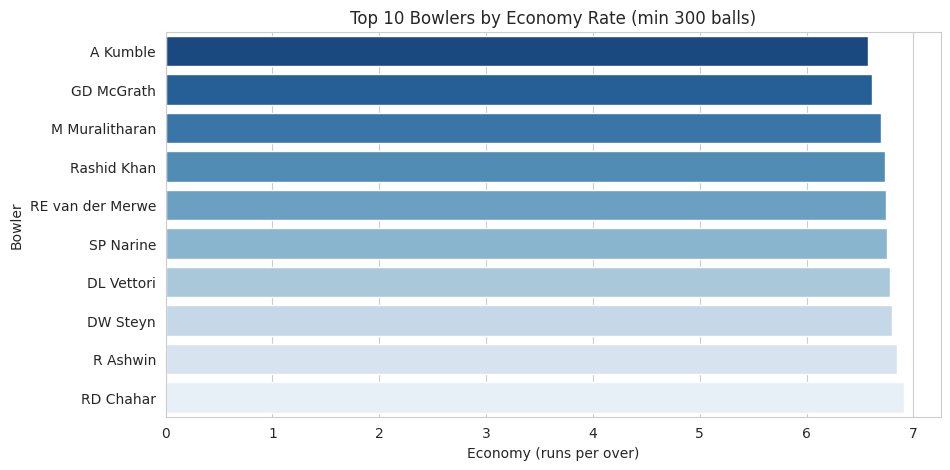

In [42]:
plt.figure(figsize=(10, 5))
sns.barplot(x=best_economy["economy"], y=best_economy.index, hue=best_economy.index, palette="Blues_r", legend=False)
plt.title("Top 10 Bowlers by Economy Rate (min 300 balls)")
plt.xlabel("Economy (runs per over)")
plt.ylabel("Bowler")
plt.show()

## 8. Which bowlers bowl the most dot balls?

In [43]:
dots = data[data["legal_ball"] & (data["total_runs"] == 0)]
top_dots = dots["bowler"].value_counts().head(10)

print("Most dot balls:", top_dots.index[0], "->", top_dots.iloc[0])
top_dots

Most dot balls: Harbhajan Singh -> 1244


,count
bowler,
Harbhajan Singh,1244
SL Malinga,1144
B Kumar,1116
A Mishra,1108
PP Chawla,1100
P Kumar,1075
R Ashwin,1067
SP Narine,1038
DW Steyn,996


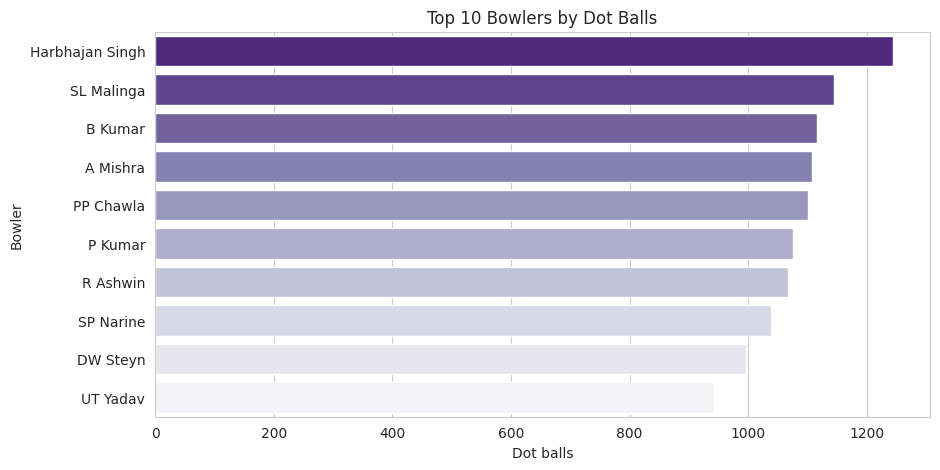

In [44]:
plt.figure(figsize=(10, 5))
sns.barplot(x=top_dots.values, y=top_dots.index, hue=top_dots.index, palette="Purples_r", legend=False)
plt.title("Top 10 Bowlers by Dot Balls")
plt.xlabel("Dot balls")
plt.ylabel("Bowler")
plt.show()

## 9. Match phases: Powerplay vs Middle vs Death

In [45]:
phase_order = ["Powerplay (1-6)", "Middle (7-15)", "Death (16-20)"]

phase_stats = data.groupby("phase").agg(
    runs=("total_runs", "sum"),
    balls=("legal_ball", "sum"),
    wickets=("player_dismissed", "count")
).loc[phase_order]

phase_stats["run_rate"] = (phase_stats["runs"] / (phase_stats["balls"] / 6)).round(2)
phase_stats["balls_per_wicket"] = (phase_stats["balls"] / phase_stats["wickets"]).round(1)
phase_stats

,runs,balls,wickets,run_rate,balls_per_wicket
phase,,,,,
Powerplay (1-6),69831,54384,2177,7.70,25.0
Middle (7-15),101981,79878,3359,7.66,23.8
Death (16-20),63478,38697,3298,9.84,11.7


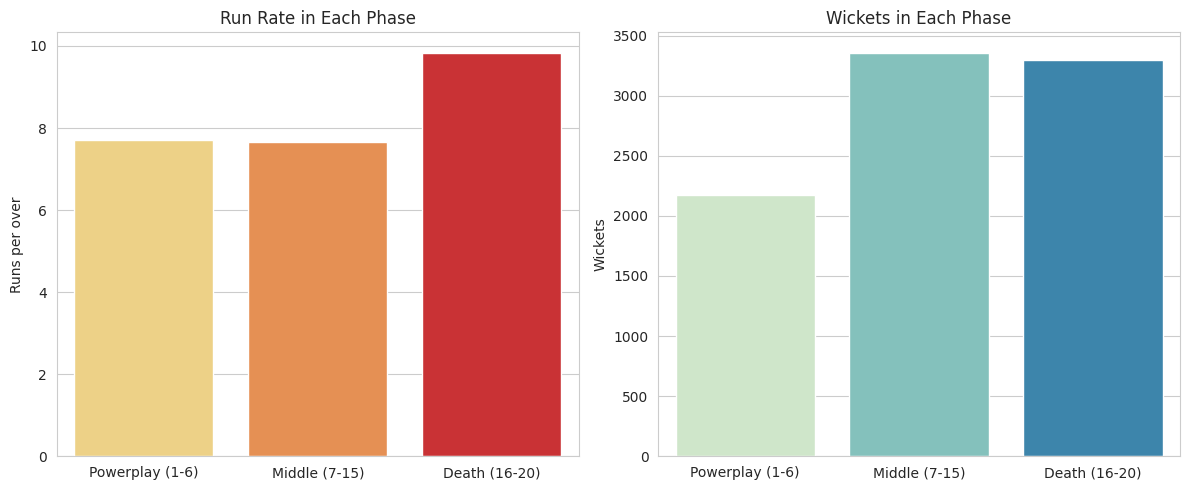

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(x=phase_stats.index, y=phase_stats["run_rate"], hue=phase_stats.index,
            palette="YlOrRd", legend=False, ax=axes[0])
axes[0].set_title("Run Rate in Each Phase")
axes[0].set_ylabel("Runs per over")
axes[0].set_xlabel("")

sns.barplot(x=phase_stats.index, y=phase_stats["wickets"], hue=phase_stats.index,
            palette="GnBu", legend=False, ax=axes[1])
axes[1].set_title("Wickets in Each Phase")
axes[1].set_ylabel("Wickets")
axes[1].set_xlabel("")

plt.tight_layout()
plt.show()

## 10. Team run rate in each phase

In [47]:
team_phase = data.groupby(["batting_team", "phase"]).agg(
    runs=("total_runs", "sum"),
    balls=("legal_ball", "sum")
)
team_phase["run_rate"] = team_phase["runs"] / (team_phase["balls"] / 6)

# rows = teams, columns = phases
rr_table = team_phase["run_rate"].unstack()[phase_order].round(2)
rr_table

phase,Powerplay (1-6),Middle (7-15),Death (16-20)
batting_team,,,
Chennai Super Kings,7.62,7.74,10.35
Deccan Chargers,7.59,7.33,9.25
Delhi Capitals,8.70,7.63,10.04
Delhi Daredevils,7.65,7.58,9.70
Gujarat Lions,8.61,8.02,9.28
Kings XI Punjab,7.84,7.93,9.54
Kochi Tuskers Kerala,8.10,7.02,7.91
Kolkata Knight Riders,7.82,7.64,9.90
Mumbai Indians,7.57,7.62,10.30


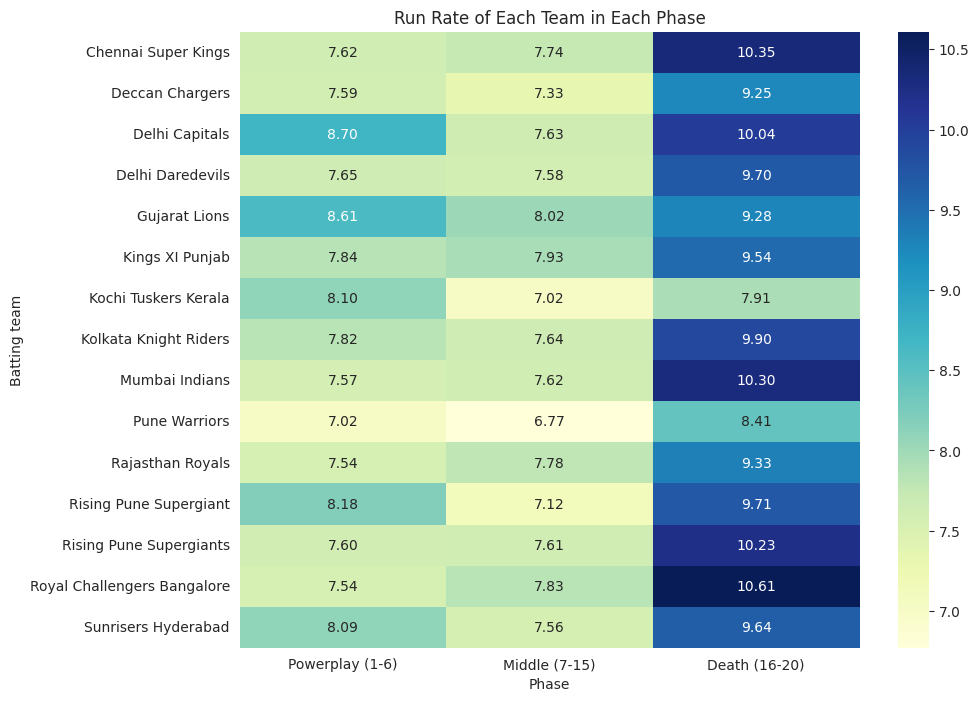

In [48]:
plt.figure(figsize=(10, 8))
sns.heatmap(rr_table, annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Run Rate of Each Team in Each Phase")
plt.xlabel("Phase")
plt.ylabel("Batting team")
plt.show()

**Observation:** the heatmap makes it easy to compare teams. A darker box means a higher run rate. Teams that are dark in the Death column are the best finishers.

## 11. First innings vs second innings

In [49]:
# Only innings 1 and 2 (super overs are ignored)
main = data[data["inning"].isin([1, 2])]

inn = main.groupby("inning").agg(
    runs=("total_runs", "sum"),
    balls=("legal_ball", "sum"),
    wickets=("player_dismissed", "count"),
    matches=("match_id", "nunique")
)

inn["avg_score"] = (inn["runs"] / inn["matches"]).round(2)
inn["run_rate"] = (inn["runs"] / (inn["balls"] / 6)).round(2)
inn

,runs,balls,wickets,matches,avg_score,run_rate
inning,,,,,,
1,122763,89613,4604,756,162.38,8.22
2,112321,83256,4216,754,148.97,8.09


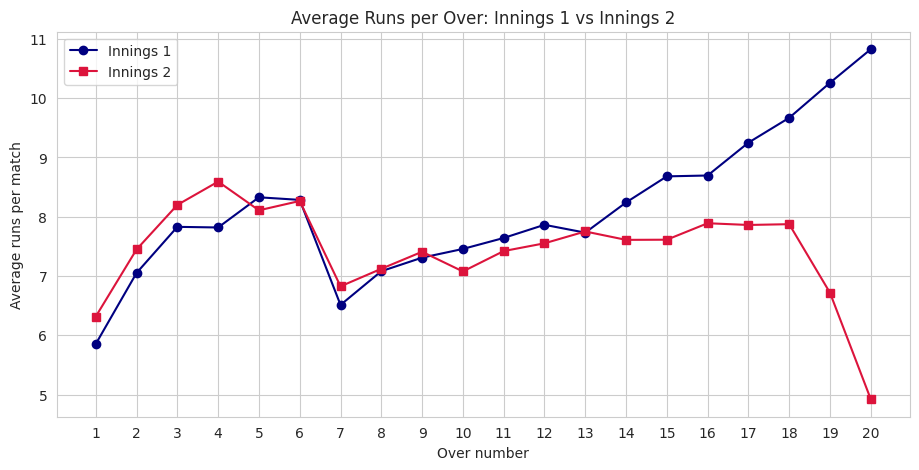

In [50]:
# Average runs in each over, innings 1 vs innings 2
over_inn = main.groupby(["over", "inning"])["total_runs"].sum().unstack()
over_inn = over_inn / main["match_id"].nunique()      # average per match

plt.figure(figsize=(11, 5))
plt.plot(over_inn.index, over_inn[1], marker="o", label="Innings 1", color="navy")
plt.plot(over_inn.index, over_inn[2], marker="s", label="Innings 2", color="crimson")
plt.title("Average Runs per Over: Innings 1 vs Innings 2")
plt.xlabel("Over number")
plt.ylabel("Average runs per match")
plt.xticks(over_inn.index)
plt.legend()
plt.show()

## 12. Best batting partnerships

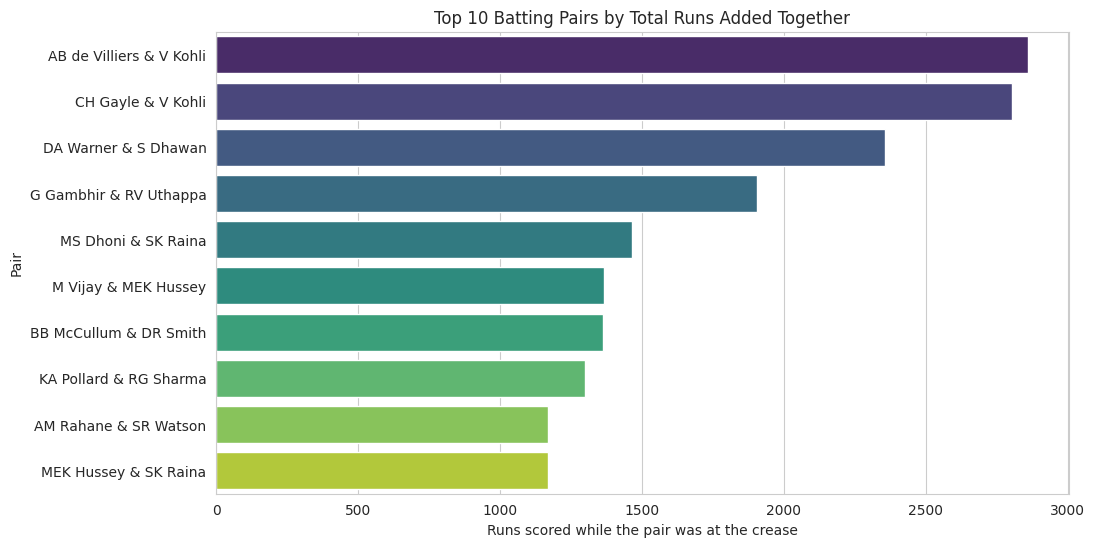

In [51]:
# Step: Calculate batting partnerships
# Sort the batsman and non_striker names alphabetically so that (A, B) and (B, A) are grouped together
pair_data = data.dropna(subset=["batsman", "non_striker"]).copy()
pair_data["pair"] = pair_data.apply(lambda row: " & ".join(sorted([str(row["batsman"]), str(row["non_striker"])])), axis=1)

# Sum the total runs scored while each pair was at the crease
top_pairs = pair_data.groupby("pair")["total_runs"].sum().sort_values(ascending=False).head(10)

# Plot the top partnerships
plt.figure(figsize=(11, 6))
sns.barplot(x=top_pairs.values, y=top_pairs.index, hue=top_pairs.index, palette="viridis", legend=False)
plt.title("Top 10 Batting Pairs by Total Runs Added Together")
plt.xlabel("Runs scored while the pair was at the crease")
plt.ylabel("Pair")
plt.show()

## 13. Wickets and fielders

In [52]:
# Which fielders took the most catches?
catches = data[data["dismissal_kind"].isin(["caught", "caught and bowled"])]
top_fielders = catches["fielder"].value_counts().head(10)

print("Most catches (incl. caught & bowled):", top_fielders.index[0], "->", top_fielders.iloc[0])
top_fielders

Most catches (incl. caught & bowled): KD Karthik -> 109


,count
fielder,
KD Karthik,109
SK Raina,99
MS Dhoni,98
AB de Villiers,93
RV Uthappa,84
RG Sharma,82
KA Pollard,76
V Kohli,73
PA Patel,69


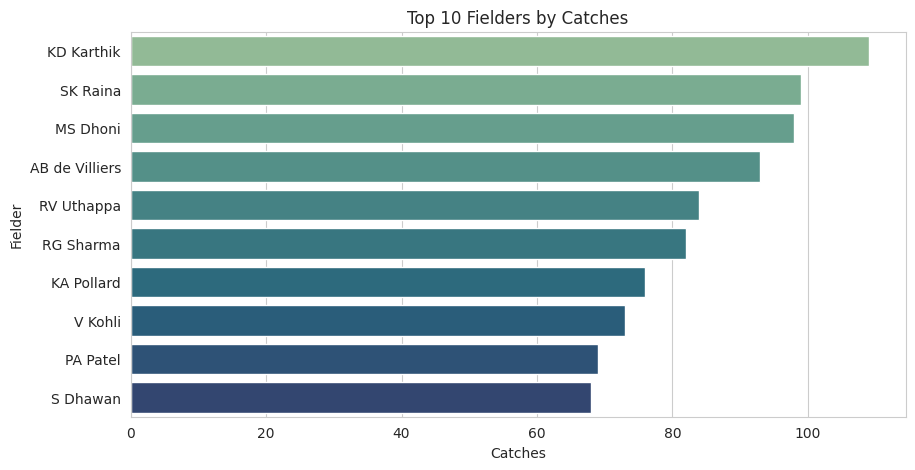

In [53]:
plt.figure(figsize=(10, 5))
sns.barplot(x=top_fielders.values, y=top_fielders.index, hue=top_fielders.index, palette="crest", legend=False)
plt.title("Top 10 Fielders by Catches")
plt.xlabel("Catches")
plt.ylabel("Fielder")
plt.show()

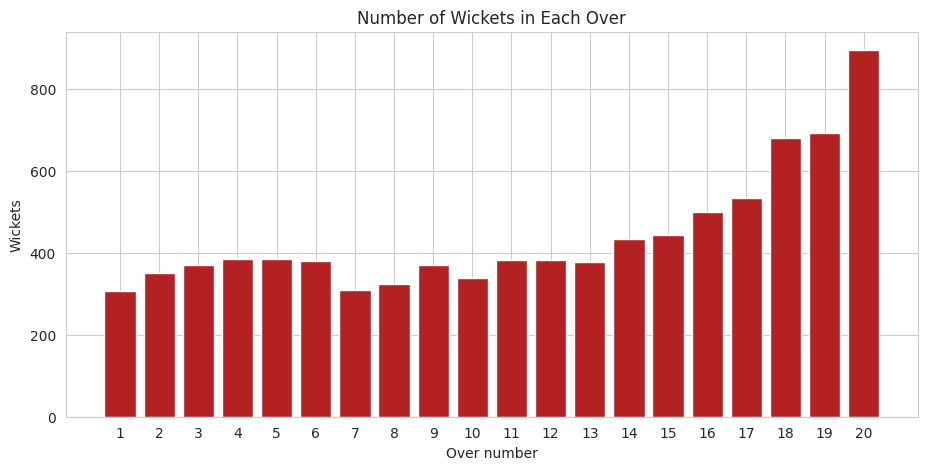

In [54]:
# How do wickets fall in each over? (1-20)
wickets_per_over = data[data["player_dismissed"].notnull()].groupby("over").size()

plt.figure(figsize=(11, 5))
plt.bar(wickets_per_over.index, wickets_per_over.values, color="firebrick")
plt.title("Number of Wickets in Each Over")
plt.xlabel("Over number")
plt.ylabel("Wickets")
plt.xticks(wickets_per_over.index)
plt.show()

## 14. Final summary

In [55]:
print("========== IPL ANALYSIS SUMMARY (PART 2) ==========")
print("Matches                  :", matches)
print("Avg runs per match       :", round(match_runs.mean(), 2))
print("Best strike rate         :", top_sr.index[0], f"({top_sr['strike_rate'].iloc[0]})")
print("Best economy             :", best_economy.index[0], f"({best_economy['economy'].iloc[0]})")
print("Most dot balls           :", top_dots.index[0], f"({top_dots.iloc[0]})")
print("Highest run-rate phase   :", phase_stats['run_rate'].idxmax(), f"({phase_stats['run_rate'].max()})")
print("Top partnership          :", top_pairs.index[0], f"({top_pairs.iloc[0]} runs)")
print("Top fielder (catches)    :", top_fielders.index[0], f"({top_fielders.iloc[0]})")
print("Innings 1 avg score      :", inn.loc[1, 'avg_score'])
print("Innings 2 avg score      :", inn.loc[2, 'avg_score'])

========== IPL ANALYSIS SUMMARY (PART 2) ==========
Matches                  : 756
Avg runs per match       : 311.23
Best strike rate         : AD Russell (191.64)
Best economy             : A Kumble (6.58)
Most dot balls           : Harbhajan Singh (1244)
Highest run-rate phase   : Death (16-20) (9.84)
Top partnership          : AB de Villiers & V Kohli (2860 runs)
Top fielder (catches)    : KD Karthik (109)
Innings 1 avg score      : 162.38
Innings 2 avg score      : 148.97


## Conclusion
- We created helper columns (legal ball, faced ball, bowler runs and match phase) to calculate fair statistics.
- We measured batters by strike rate, boundary % and dot-ball %, and bowlers by economy rate and dot balls.
- We compared Powerplay, Middle and Death overs, and innings 1 with innings 2.
- We found the best partnerships and the best fielders using Pandas.
- We used bar charts, a histogram, a scatter plot, a line chart and a heatmap to show the patterns.